# Decision Analysis

This notebook computes the results of the thesis (Chapter 7): the optimal dike design under uncertain sea level rise and the value of flexibility, for two flexibility concepts and their sensitivity to all parameters.

**Problem** (thesis Chapter 3 and 6). An existing dike with capacity $h_{-1}$ is upgraded at the decision times $t_0, t_1, \dots$ (every 10 years). At each decision, the sea level rise $\theta_i$ observed so far is known, and the dike can be raised to $h_i \ge h_{i-1}$. At the first decision, a flexibility is chosen that makes later upgrades cheaper. The objective is to minimize the expected discounted cost of upgrades and flood losses. It is solved by backward induction over a lattice of sea level rise states.

**Value of flexibility.** The *inflexible dike* is the best design without flexibility; the *flexible dike* is the best design overall. The value of flexibility is $\mathrm{VoF} = E[\text{cost}_\text{inflexible}] - E[\text{cost}_\text{flexible}] \ge 0$; the relative VoF divides it by $E[\text{cost}_\text{inflexible}]$. Both dikes may also wait (deferral: no upgrade at the first decision).

**Flexibility concepts** (thesis Chapter 5):
- *Retention flexibility* $\tilde{\varphi} \in [0, 1]$ (`RetentionCostModel`): the part of the existing dike that is kept in an upgrade, $c_a = c + v(h_i - \tilde{\varphi} h_{i-1})$.
- *Land availability* $h_\mathrm{max}$ (`LandCostModel`): the height up to which land for the dike footprint is reserved, which protects it from encroachment.

## Implementation

The model consists of three submodels, combined by `backward_induction`:

```
SeaLevelRiseModel (source.sea_level_rise_model) ─┐
RiskModel         (source.risk_model)            ├─> backward_induction ─> RewardsTable ─> extract_optimal_designs
CostModel         (source.cost_model)            ┘   (source.decision_analysis)            (VoF, inflexible and flexible dike)
```

Main calls:

```python
_, rewards = backward_induction(sea_level_rise_model, risk_model, cost_model, backward_kwargs)
vof, inflexible, flexible = extract_optimal_designs(rewards)   # designs as (h_0, flexibility, reward)
swept = sweep_designs("discount_rate", [0.01, 0.0225, 0.05], sea_level_rise_model, risk_model, cost_model, backward_kwargs)
```

All results are shown as expected cost (negative rewards). Expensive cells are cached with `%%cache` (see `source/cellcache_magic.py`). The first run of the sensitivity analysis takes several hours.

In [1]:
%load_ext source.cellcache_magic

import matplotlib.pyplot as plt
import numpy as np

from source.cost_model import LandCostModel, RetentionCostModel
from source.decision_analysis import (
    backward_induction,
    compare_learning_models,
    cost_level_pairs,
    cost_ratio_pairs,
    design_summary,
    match_ylim_spans,
    plot_cost_by_capacity,
    plot_cost_by_flexibility,
    plot_optimal_decisions_along_trajectories,
    plot_optimal_decisions_by_model,
    plot_sweep,
    sweep_designs,
    sweep_results,
    sweep_summary,
)
from source.risk_model import StandardRiskModel
from source.sea_level_rise_model import (
    DirectFitSeaLevelRiseModel,
    LinearGrowthSeaLevelRiseModel,
    StaticGridSeaLevelRiseModel,
)

## Assumptions

Baseline parameters of the thesis (Sections 4.4, 5.2, 5.3, 6.5 and Appendix A6). The retention flexibility model has two dike types; the land availability model has two land-use scenarios, both with the structurally reinforced dike, whose retention $\tilde{\varphi}$ is fixed.

In [2]:
# Sea level rise model: direct fit lattice, decisions 2025-2135 every 10 years (t_N = 2145)
sea_level_rise_model = DirectFitSeaLevelRiseModel(
    start_year=2025,
    end_year=2150,
    step=10,
    method="mixture",  # Mixture of the SSP scenarios ...
    distribution=None,  # ... each fitted with a Pearson type IV distribution
    weights=[0.25, 0.5, 0.25],  # Scenario weights w (SSP1-2.6, SSP2-4.5, SSP5-8.5)
    extrapolate=True,
    p=0.5,  # Transition probability p
)
LEARNING_MODELS = {
    "direct_fit": DirectFitSeaLevelRiseModel,
    "static_grid": StaticGridSeaLevelRiseModel,
    "linear_growth": LinearGrowthSeaLevelRiseModel,
}

# Risk model (Jongejan et al. 2026)
risk_model = StandardRiskModel(
    r=2.25,  # Scaling factor of sea level rise [-]
    a=0.0,  # Location of the extreme water level [m]
    b=1 / np.log(10),  # Scale of the extreme water level [m]
    D=10e9,  # Flood damage [€]
)

# Retention flexibility model: dike types
DIKE_TYPES = {
    "earthen": {"c": 10e6, "v": 60e6, "phi_minus_1": 0.8, "kappa_1": 10.0, "kappa_2": 1.0},
    "structurally_reinforced": {"c": 100e6, "v": 100e6, "phi_minus_1": 0.2, "kappa_1": 5.0, "kappa_2": 0.5},
}  # c [€], v [€/m], existing dike retention [-], footprint coefficients (land model only) [-], [1/m]
PHI_VALUES = tuple(float(phi) for phi in np.linspace(0, 1, 21))  # Retention of the new dike [-]

# Land availability model: land-use scenarios
LAND_SCENARIOS = {
    "rural": {"W_available_0": 150.0, "lambda_enc": 1.0, "C_built": 1e6},
    "urban": {"W_available_0": 100.0, "lambda_enc": 5.0, "C_built": 1e7},
}  # Open land width [m], encroachment rate [m/yr], cost of built-up land [€/m]
C_OPEN = 1e5  # Cost of open land [€/m]
LAND_DIKE_TYPE = "structurally_reinforced"

# Decision problem
backward_kwargs = {
    "discount_rate": 0.0225,  # rho [-]
    "h_minus_1": 3.0,  # Existing dike capacity [m]
    "max_possible_h": 10.0,  # Largest upgrade considered [m]
    "h_step": 0.1,  # Height grid [m]
}
land_backward_kwargs = {**backward_kwargs, "h_step": 0.25}  # Coarser grid: h_max adds a dimension

# Sample trajectories shown in the results (about the 9th and 98th percentile in 2150)
trajectories = list(sea_level_rise_model.sample_trajectories(500, seed=42))
TRAJECTORIES = {"Low trajectory": trajectories[26], "High trajectory": trajectories[202]}

In [3]:
retention_cost_models = {
    name: RetentionCostModel(c=d["c"], v=d["v"], phi_minus_1=d["phi_minus_1"], phi_values=PHI_VALUES)
    for name, d in DIKE_TYPES.items()
}

land_dike = DIKE_TYPES[LAND_DIKE_TYPE]
land_cost_models = {
    name: LandCostModel(
        inner=RetentionCostModel(
            c=land_dike["c"],
            v=land_dike["v"],
            phi_minus_1=land_dike["phi_minus_1"],
            phi_values=(land_dike["phi_minus_1"],),  # Retention fixed: land is the only flexibility
        ),
        W_available_0=s["W_available_0"],
        lambda_enc=s["lambda_enc"],
        C_open=C_OPEN,
        C_built=s["C_built"],
        kappa_1=land_dike["kappa_1"],
        kappa_2=land_dike["kappa_2"],
        h_ref=backward_kwargs["h_minus_1"],
    )
    for name, s in LAND_SCENARIOS.items()
}

## Retention Flexibility

Optimal designs of both dike types (thesis Section 7.1). The flexible dike chooses full retention $\tilde{\varphi} = 1$, since flexibility itself is not priced.

In [4]:
%%cache retention_baselines
retention_rewards = {
    name: backward_induction(sea_level_rise_model, risk_model, cost_model, backward_kwargs)[1]
    for name, cost_model in retention_cost_models.items()
}

[cache hit: 'retention_baselines' (e661706aec)]


In [26]:
_ = design_summary(retention_rewards)

Case                     E[cost] inflexible [M€]    E[cost] flexible [M€]    VoF [M€]    Relative VoF [%]    h_0 inflexible [cm]    h_0 flexible [cm]    phi_0 flexible    Inflexible waits    Flexible waits
-----------------------  -------------------------  -----------------------  ----------  ------------------  ---------------------  -------------------  ----------------  ------------------  ----------------
earthen                  237.4                      206.8                    30.5        12.9                530                    480                  1.00              no                  no
structurally_reinforced  638.9                      603.7                    35.1        5.5                 530                    490                  1.00              no                  no


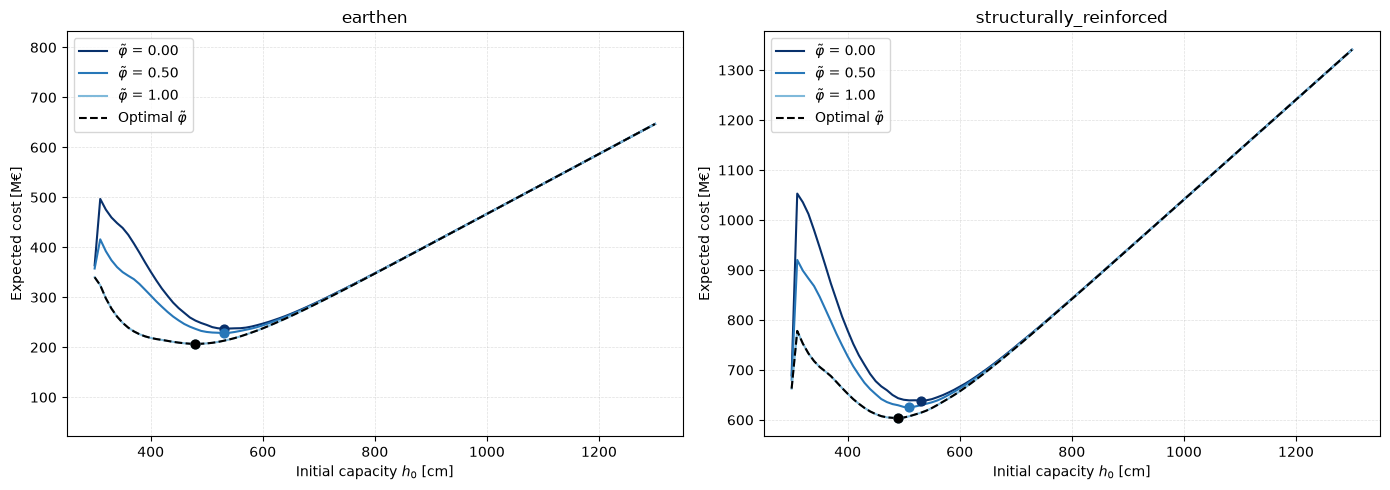

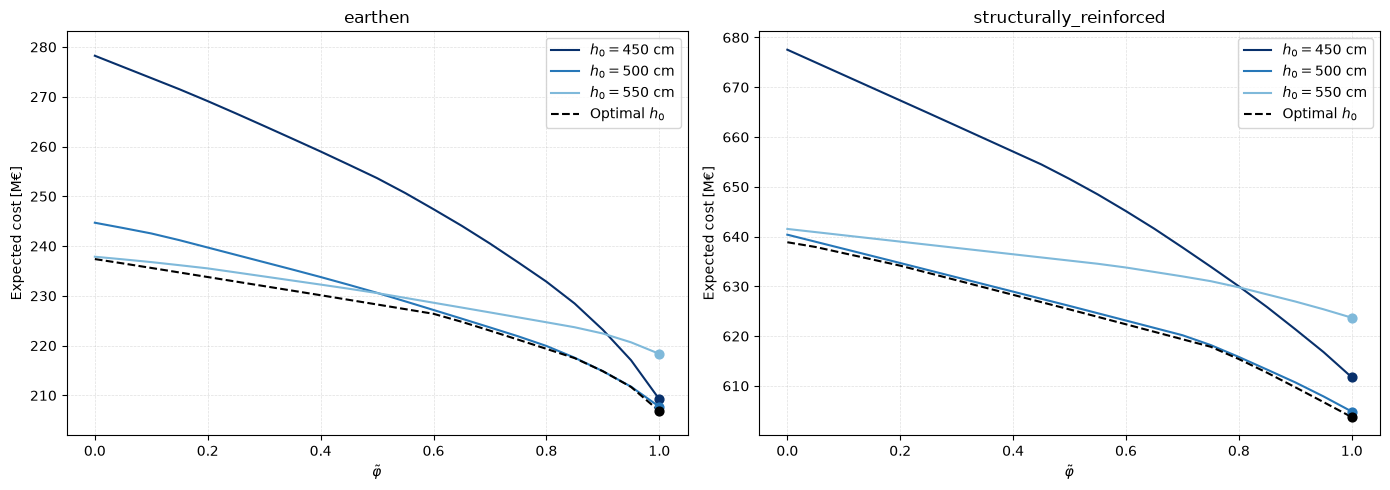

In [6]:
# Equal y-ranges (match_ylim_spans): slopes are comparable across the dike types
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, rewards) in zip(axes, retention_rewards.items()):
    plot_cost_by_capacity(rewards, flex_values=(0.0, 0.5, 1.0), title=name, ax=ax)
match_ylim_spans(axes)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, rewards) in zip(axes, retention_rewards.items()):
    plot_cost_by_flexibility(rewards, title=name, ax=ax)
match_ylim_spans(axes)
fig.tight_layout()
plt.show()

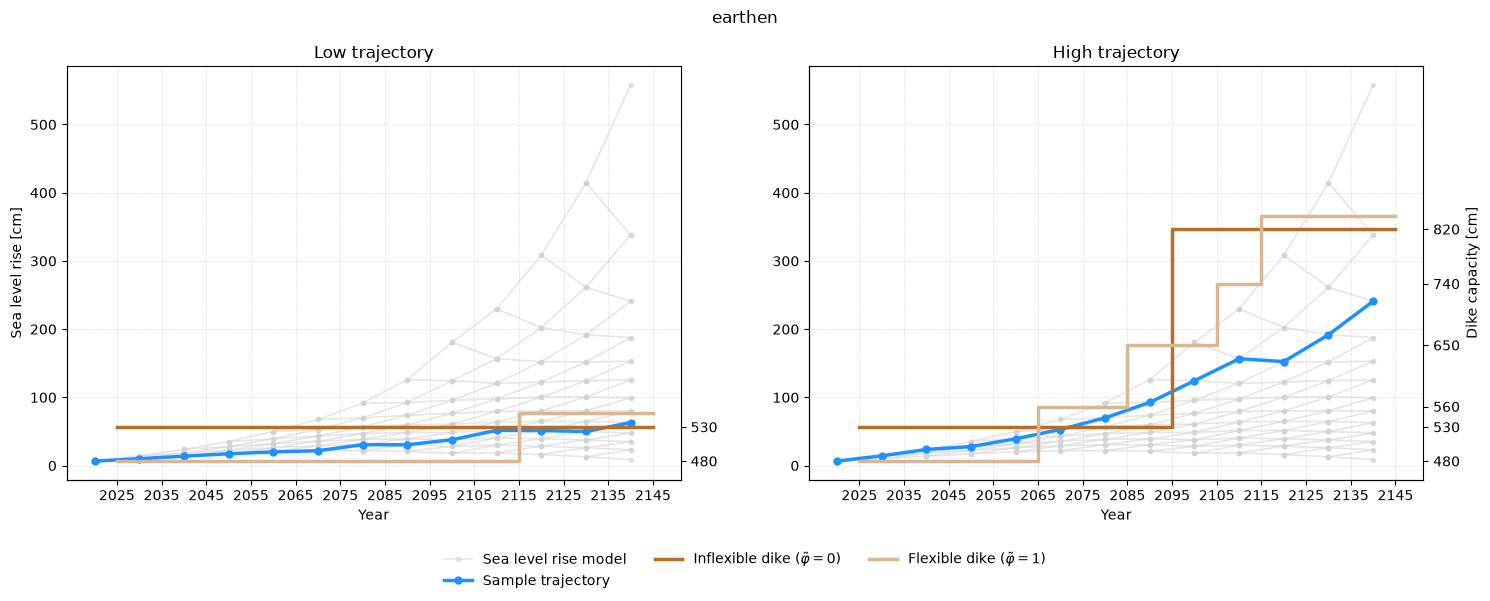

Design      h_0 [cm]    phi_0    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost (Low trajectory) [M€]    Upgrades (Low trajectory)    Mean upgrade (Low trajectory) [cm]    Realized cost (High trajectory) [M€]    Upgrades (High trajectory)    Mean upgrade (High trajectory) [cm]
----------  ----------  -------  --------------  ----------  ------------------  -------------------------------------  ---------------------------  ------------------------------------  --------------------------------------  ----------------------------  -------------------------------------
Inflexible  530         0.00     237.4           0.0         0.0                 192.9                                  1                            230                                   331.9                                   2                             260
Flexible    480         1.00     206.8           30.5        12.9                182.9                                  2                            12

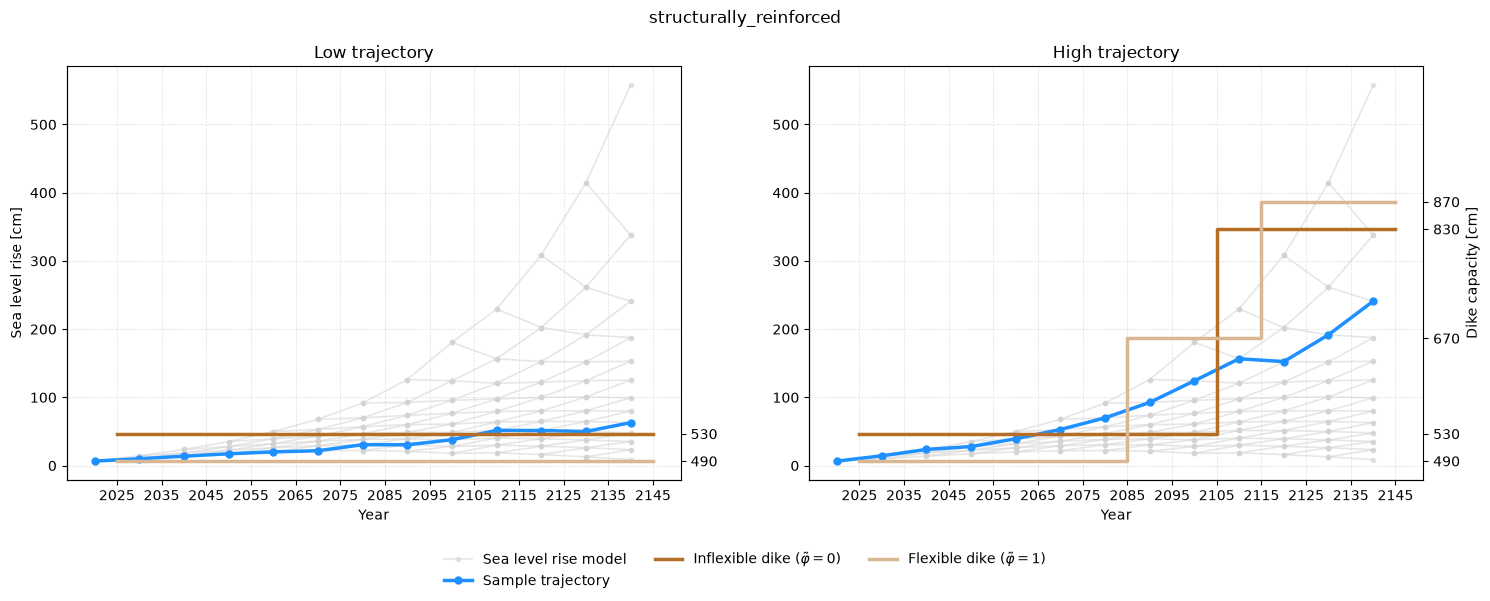

Design      h_0 [cm]    phi_0    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost (Low trajectory) [M€]    Upgrades (Low trajectory)    Mean upgrade (Low trajectory) [cm]    Realized cost (High trajectory) [M€]    Upgrades (High trajectory)    Mean upgrade (High trajectory) [cm]
----------  ----------  -------  --------------  ----------  ------------------  -------------------------------------  ---------------------------  ------------------------------------  --------------------------------------  ----------------------------  -------------------------------------
Inflexible  530         0.00     638.9           0.0         0.0                 578.9                                  1                            230                                   824.6                                   2                             265
Flexible    490         1.00     603.7           35.1        5.5                 552.4                                  1                            19

In [7]:
for name, rewards in retention_rewards.items():
    _ = plot_optimal_decisions_along_trajectories(
        rewards, TRAJECTORIES, sea_level_rise_model, risk_model, retention_cost_models[name], backward_kwargs, title=name,
    )

## Land Availability

Optimal designs of both land-use scenarios (thesis Section 7.2). Reserving land is free, so the flexible dike reserves up to the top of the height grid. For a clearer plot, the urban flexible dike is shown with a reservation up to $h_\mathrm{max,0} = 9$ m, as in the thesis.

In [8]:
%%cache land_baselines
land_rewards = {
    name: backward_induction(sea_level_rise_model, risk_model, cost_model, land_backward_kwargs)[1]
    for name, cost_model in land_cost_models.items()
}

[cache hit: 'land_baselines' (3e89e6d5fb)]


In [9]:
_ = design_summary(land_rewards)

Case    E[cost] inflexible [M€]    E[cost] flexible [M€]    VoF [M€]    Relative VoF [%]    h_0 inflexible [cm]    h_0 flexible [cm]    h_max_0 flexible [cm]    Inflexible waits    Flexible waits
------  -------------------------  -----------------------  ----------  ------------------  ---------------------  -------------------  -----------------------  ------------------  ----------------
rural   636.0                      636.0                    0.0         0.0                 500                    500                  1300                     no                  no
urban   642.6                      636.0                    6.6         1.0                 525                    500                  1300                     no                  no


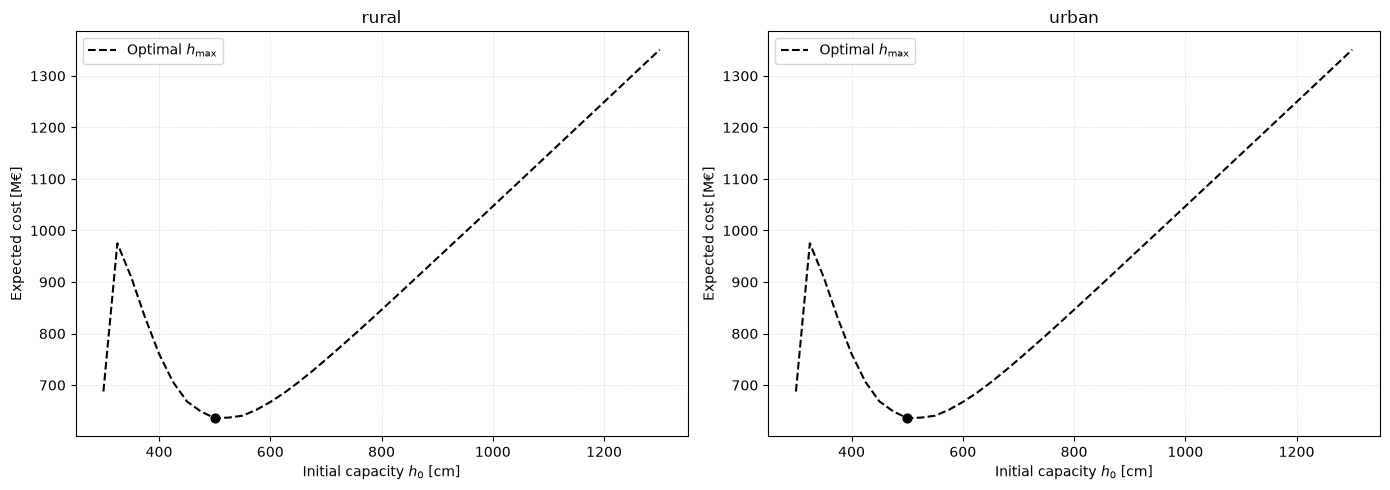

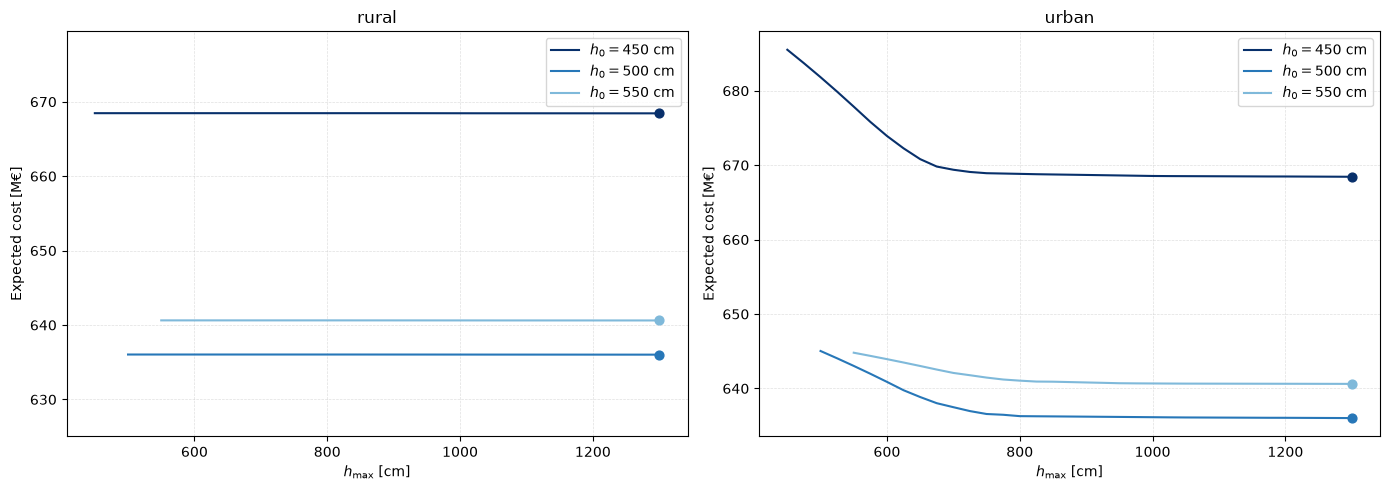

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, rewards) in zip(axes, land_rewards.items()):
    plot_cost_by_capacity(rewards, title=name, ax=ax)
match_ylim_spans(axes)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, rewards) in zip(axes, land_rewards.items()):
    plot_cost_by_flexibility(rewards, optimal_h_0=False, title=name, ax=ax)
match_ylim_spans(axes)
fig.tight_layout()
plt.show()

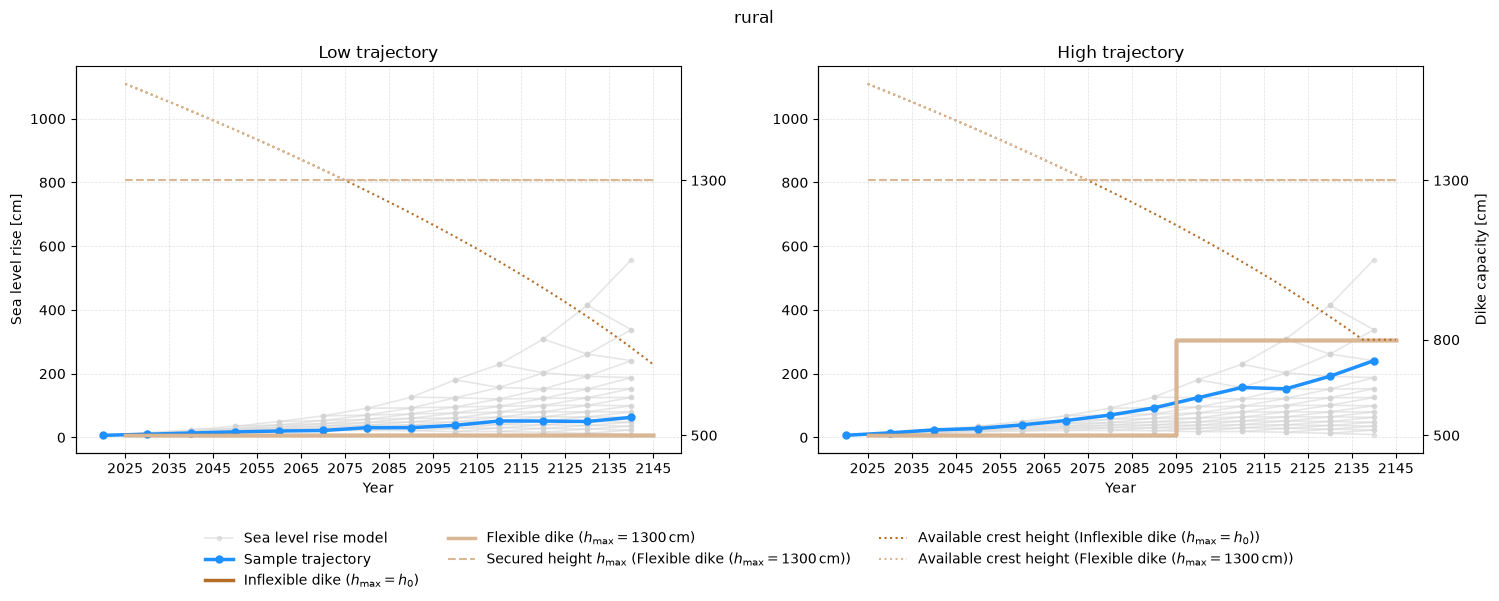

Design      h_0 [cm]    h_max_0 [cm]    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost (Low trajectory) [M€]    Upgrades (Low trajectory)    Mean upgrade (Low trajectory) [cm]    Realized cost (High trajectory) [M€]    Upgrades (High trajectory)    Mean upgrade (High trajectory) [cm]
----------  ----------  --------------  --------------  ----------  ------------------  -------------------------------------  ---------------------------  ------------------------------------  --------------------------------------  ----------------------------  -------------------------------------
Inflexible  500         500             636.0           0.0         0.0                 559.0                                  1                            200                                   788.3                                   2                             250
Flexible    500         1300            636.0           0.0         0.0                 559.0                                  1  

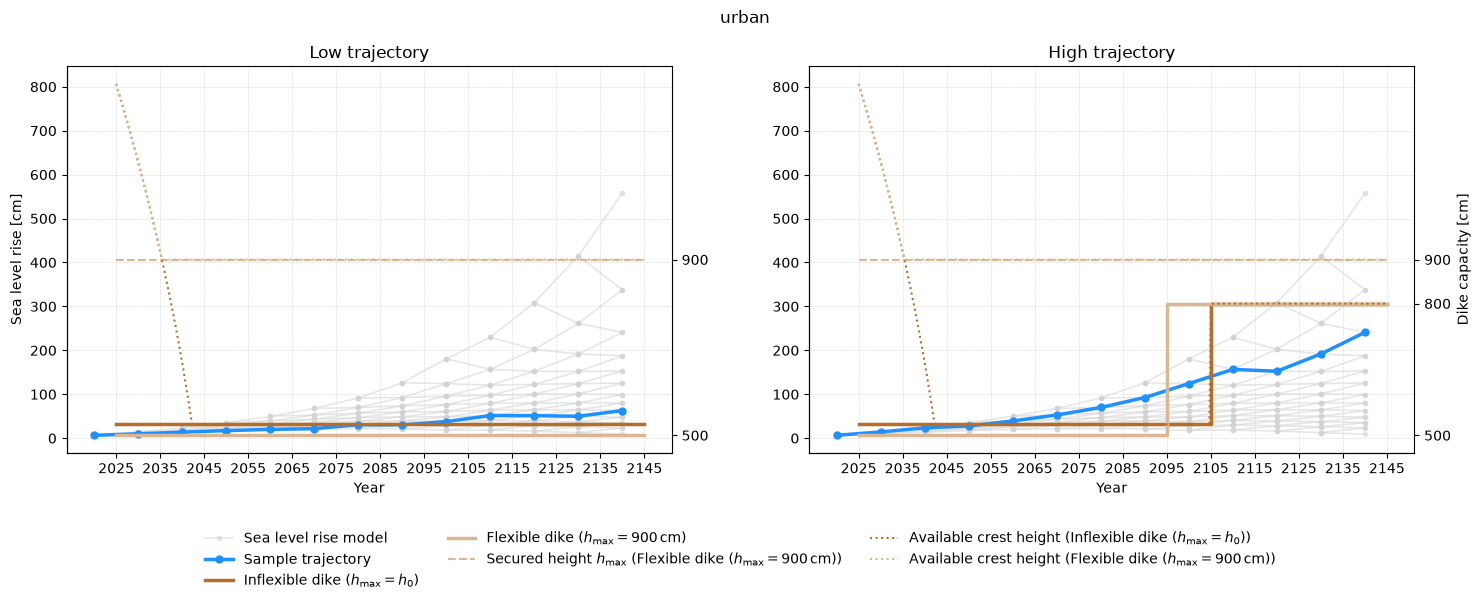

Design      h_0 [cm]    h_max_0 [cm]    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost (Low trajectory) [M€]    Upgrades (Low trajectory)    Mean upgrade (Low trajectory) [cm]    Realized cost (High trajectory) [M€]    Upgrades (High trajectory)    Mean upgrade (High trajectory) [cm]
----------  ----------  --------------  --------------  ----------  ------------------  -------------------------------------  ---------------------------  ------------------------------------  --------------------------------------  ----------------------------  -------------------------------------
Inflexible  525         525             642.6           0.0         0.0                 576.4                                  1                            225                                   860.2                                   2                             250
Flexible    500         900             636.2           6.4         1.0                 559.0                                  1  

In [11]:
LAND_RESERVATIONS = {"urban": 9.0}  # h_max_0 [m] of the flexible dike in the plots (None: optimal)

for name, rewards in land_rewards.items():
    _ = plot_optimal_decisions_along_trajectories(
        rewards, TRAJECTORIES, sea_level_rise_model, risk_model, land_cost_models[name], land_backward_kwargs,
        flexibility=LAND_RESERVATIONS.get(name), title=name,
    )

## Learning Models

The retention flexibility of the earthen dike with the static grid (no learning) and linear growth (all learning at the first step) sea level rise models (thesis Section 4.2).

In [12]:
%%cache learning_models
learning_results = compare_learning_models(
    sea_level_rise_model, risk_model, retention_cost_models["earthen"], backward_kwargs, LEARNING_MODELS
)

[cache hit: 'learning_models' (bb2a7e643c)]


In [13]:
_ = design_summary({name: result["rewards"] for name, result in learning_results.items()})

Case           E[cost] inflexible [M€]    E[cost] flexible [M€]    VoF [M€]    Relative VoF [%]    h_0 inflexible [cm]    h_0 flexible [cm]    phi_0 flexible    Inflexible waits    Flexible waits
-------------  -------------------------  -----------------------  ----------  ------------------  ---------------------  -------------------  ----------------  ------------------  ----------------
direct_fit     237.4                      206.8                    30.5        12.9                530                    480                  1.00              no                  no
static_grid    257.7                      214.8                    42.9        16.7                610                    480                  1.00              no                  no
linear_growth  244.6                      212.9                    31.6        12.9                550                    490                  1.00              no                  no


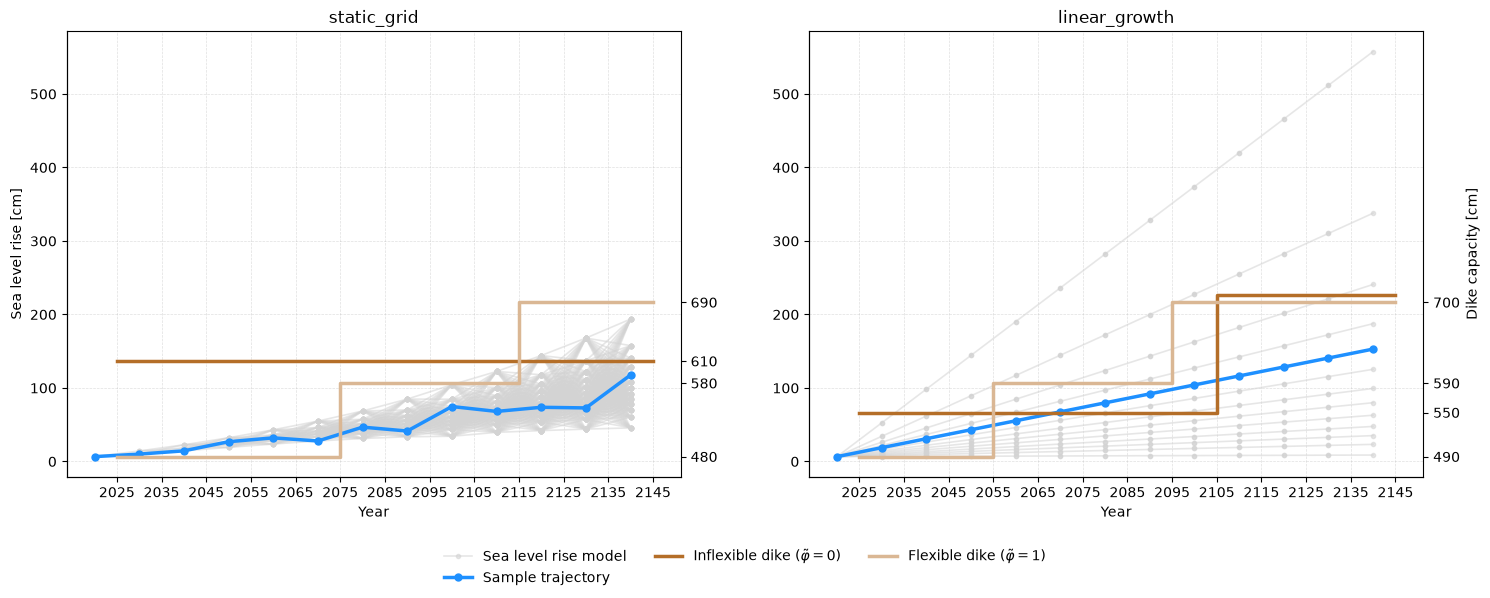

static_grid
Design      h_0 [cm]    phi_0    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost [M€]    Upgrades    Mean upgrade [cm]
----------  ----------  -------  --------------  ----------  ------------------  --------------------  ----------  -------------------
Inflexible  610         0.00     257.7           0.0         0.0                 237.8                 1           310
Flexible    480         1.00     214.8           42.9        16.7                205.5                 3           130

linear_growth
Design      h_0 [cm]    phi_0    E[cost] [M€]    VoF [M€]    Relative VoF [%]    Realized cost [M€]    Upgrades    Mean upgrade [cm]
----------  ----------  -------  --------------  ----------  ------------------  --------------------  ----------  -------------------
Inflexible  550         0.00     244.6           0.0         0.0                 310.9                 2           205
Flexible    490         1.00     212.9           31.6        12.9               

In [14]:
SAMPLES = {"static_grid": 7, "linear_growth": 15}  # Index in sample_trajectories(100, seed=42)

learning_trajectories = {name: list(learning_results[name]["model"].sample_trajectories(100, seed=42))[index] for name, index in SAMPLES.items()}
_ = plot_optimal_decisions_by_model(learning_results, learning_trajectories, risk_model, retention_cost_models["earthen"], backward_kwargs)

## Sensitivity Analysis

Every parameter is varied one at a time around the baseline (thesis Sections 7.1.5 and 7.2.5). Model parameters are analyzed for their effect on the value of flexibility; numerical parameters (height step, height range, time step and end year) check the convergence of the results. The cost of a 1 m upgrade per km of dike, $\bar{c} = (c + v \cdot 1\,\mathrm{m}) / 10\,\mathrm{km}$, varies $c$ and $v$ together at a fixed ratio $c/v$. Shaded areas indicate that waiting (deferral) at the first decision is optimal. All sweep plots share one y-axis; the table below each grid gives the range of the relative value of flexibility per sweep, sorted by its spread.

Each sweep is defined by `(parameter name(s), values, x-axis values, x-axis label, x-axis scale)`.

In [15]:
COST_RATIOS = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]  # c/v [m]
COST_LEVELS = [1.0, 2.0, 5.0, 10.0, 20.0, 50.0]  # c_bar [M€/km]
SWEEP_YLIM = (0.0, 20.0)  # Common relative VoF axis of all sweep plots [%]
DAMAGE_FACTORS = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]  # Multiples of the baseline damage
EMISSION_SCENARIOS = {"Low": [1.0, 0.0, 0.0], "Medium": [0.0, 1.0, 0.0], "High": [0.0, 0.0, 1.0]}


def model_sweeps(cost_model):
    # Sweeps of the model parameters around the baseline `cost_model` (retention or land model)
    land = isinstance(cost_model, LandCostModel)
    retention = cost_model.inner if land else cost_model
    c, v, D = retention.c, retention.v, risk_model.D # type: ignore
    sweeps = {}
    if land:
        sweeps |= {
            "W_available_0": ("W_available_0", [20.0, 50.0, 100.0, 200.0, 500.0], None, r"$W_\mathrm{available,0}$ [m]", "log"),
            "lambda_enc": ("lambda_enc", [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0], None, r"$\lambda_\mathrm{enc}$ [m/yr]", "log"),
            "C_open": ("C_open", [2e4, 5e4, 1e5, 2e5, 5e5], [20, 50, 100, 200, 500], r"$C_\mathrm{open}$ [k€/m]", "log"),
            "C_built": ("C_built", [1e6, 2e6, 5e6, 1e7, 2e7, 5e7, 1e8], [1, 2, 5, 10, 20, 50, 100], r"$C_\mathrm{built}$ [M€/m]", "log"),
            "kappa_1": ("kappa_1", [5.0, 10.0, 15.0, 20.0], None, r"$\kappa_1$ [-]", "linear"),
            "kappa_2": ("kappa_2", [0.5, 1.0, 1.5, 2.0], None, r"$\kappa_2$ [1/m]", "linear"),
        }
    sweeps |= {
        "c/v": (("c", "v"), cost_ratio_pairs(c, v, COST_RATIOS), COST_RATIOS, "$c/v$ [m]", "log"),
        "c_bar": (("c", "v"), cost_level_pairs(c, v, COST_LEVELS), COST_LEVELS, r"$\bar{c}$ [M€/km]", "log"),
        "h_minus_1": (
            ("h_minus_1", "h_ref") if land else "h_minus_1",
            [(h, h) if land else h for h in [1.0, 2.0, 3.0, 4.0, 5.0]],
            [100, 200, 300, 400, 500], "$h_{-1}$ [cm]", "linear",
        ),
        "phi": (
            ("phi_minus_1", "phi_values") if land else "phi_minus_1",
            [(phi, (phi,)) if land else phi for phi in [0.0, 0.2, 0.5, 0.8, 1.0]],
            [0.0, 0.2, 0.5, 0.8, 1.0], r"$\tilde{\varphi}$ [-]" if land else r"$\tilde{\varphi}_{-1}$ [-]", "linear",
        ),
        "rho": ("discount_rate", [0.005, 0.01, 0.0225, 0.05, 0.1], [0.5, 1.0, 2.25, 5.0, 10.0], r"$\rho$ [%]", "linear"),
        "D": (
            ("D", "max_possible_h"),  # Larger height range for higher damages
            [(m * D, 10.0 if m <= 1 else 15.0) for m in DAMAGE_FACTORS],
            [m * D / 1e9 for m in DAMAGE_FACTORS], "$D$ [bn€]", "log",
        ),
        "w": ("weights", list(EMISSION_SCENARIOS.values()), None, "Emission scenario", list(EMISSION_SCENARIOS)),
        "p": ("p", [0.3, 0.4, 0.5, 0.6, 0.7], None, "$p$ [-]", "linear"),
        "learning_model": ("learning_model", list(LEARNING_MODELS), None, "Learning model", list(LEARNING_MODELS)),
    }
    return sweeps


def numerical_sweeps(kwargs, land):
    # Convergence checks of the numerical parameters around the baseline `kwargs` (land: land model)
    h_steps = [0.05, 0.1, 0.25, 0.5] if land else [0.05, 0.1, 0.2, 0.5]
    end_years = [(2100, 0.1, 10), (2150, 0.1, 10), (2200, 0.2, 20), (2250, 0.2, 20), (2300, 0.25, 25)]
    return {
        "h_step": ("h_step", h_steps, [h * 100 for h in h_steps], r"$\Delta h$ [cm]", "linear"),
        "max_possible_h": ("max_possible_h", [5.0, 7.5, 10.0, 12.5, 15.0], [500, 750, 1000, 1250, 1500], r"$H_\mathrm{grid}$ [cm]", "linear"),
        "step": ("step", [5, 10, 20, 50], None, r"$\Delta t$ [yr]", "linear"),
        "end_year": (
            ("end_year", "h_step", "max_possible_h"),  # Coarser height grid for longer horizons
            [(year, kwargs["h_step"] if land else h_step, h_max) for year, h_step, h_max in end_years],
            [year - 5 for year, _, _ in end_years], "$t_N$", "linear",  # t_N = end_year - step / 2
        ),
    }


def run_sweeps(sweeps, cost_model, kwargs):
    return {
        name: sweep_designs(param, values, sea_level_rise_model, risk_model, cost_model, kwargs, LEARNING_MODELS)
        for name, (param, values, *_) in sweeps.items()
    }


def plot_sweeps(results, sweeps, title, ncols=3):
    # Grid of all sweeps on the common y-axis SWEEP_YLIM, then the summary of their relative VoF
    nrows = -(-len(results) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)
    for ax, (name, swept) in zip(axes.flat, results.items()):
        _, values, x_values, xlabel, scale = sweeps[name]
        categorical = isinstance(scale, list)
        plot_sweep(
            swept, values, x_values=list(range(len(values))) if categorical else x_values, xlabel=xlabel,
            xscale="linear" if categorical else scale, xticklabels=scale if categorical else None, ylim=SWEEP_YLIM,
            ax=ax, table=False,
        )
        ax.get_legend().remove()
    for ax in axes.flat[len(results):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    _ = sweep_summary(results)

In [16]:
%%cache sweeps_retention
retention_sweeps = {
    name: run_sweeps(model_sweeps(cost_model), cost_model, backward_kwargs)
    for name, cost_model in retention_cost_models.items()
}

[cache hit: 'sweeps_retention' (54f8da9a81)]


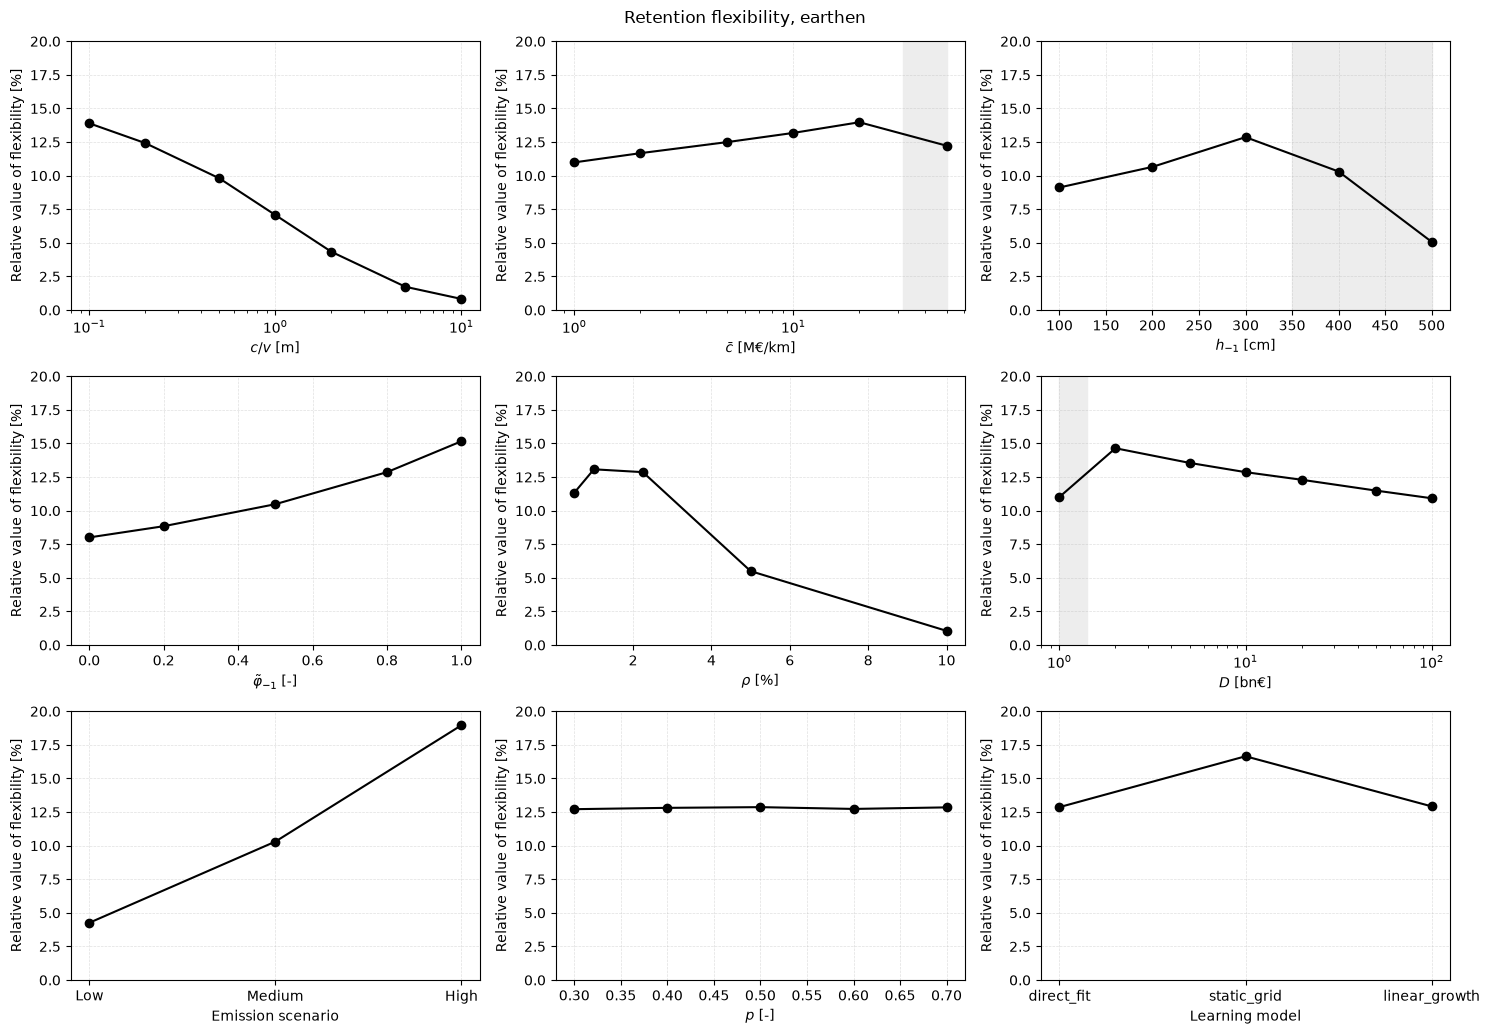

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
w               4.3        19.0       14.7
c/v             0.8        13.9       13.1
rho             1.1        13.1       12.0
h_minus_1       5.1        12.9       7.8
phi             8.0        15.2       7.2
learning_model  12.9       16.7       3.8
D               10.9       14.6       3.7
c_bar           11.0       14.0       3.0
p               12.7       12.9       0.2


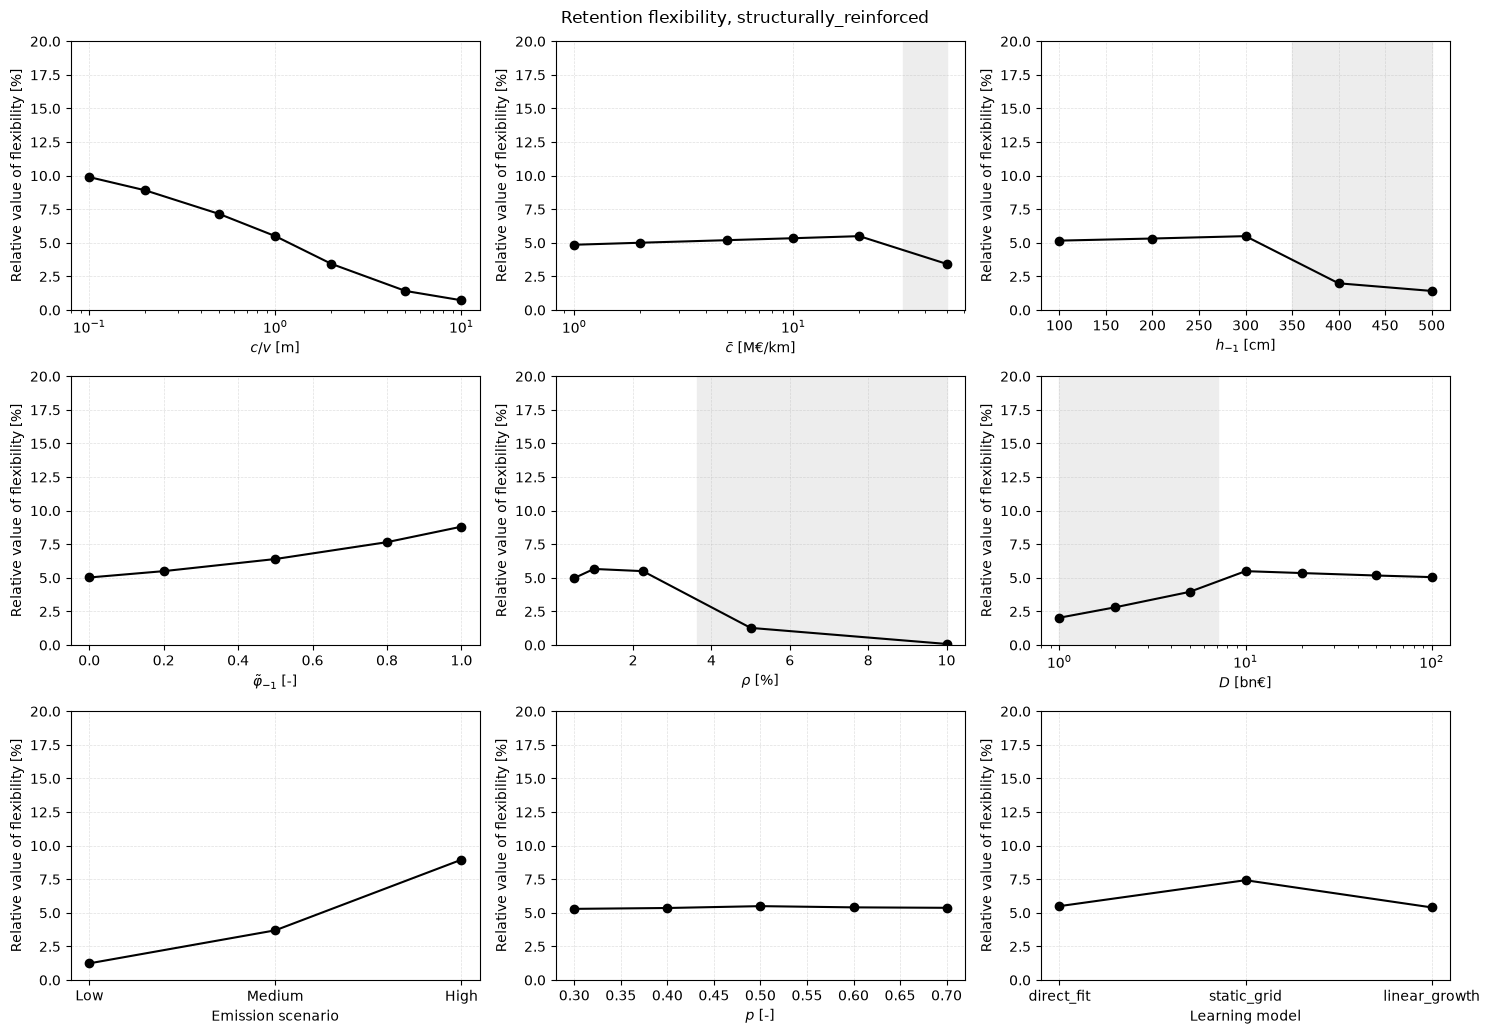

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
c/v             0.7        9.9        9.2
w               1.2        9.0        7.7
rho             0.1        5.7        5.6
h_minus_1       1.4        5.5        4.1
phi             5.0        8.8        3.8
D               2.0        5.5        3.5
c_bar           3.4        5.5        2.1
learning_model  5.4        7.4        2.0
p               5.3        5.5        0.2


In [17]:
for name, cost_model in retention_cost_models.items():
    plot_sweeps(retention_sweeps[name], model_sweeps(cost_model), f"Retention flexibility, {name}")

In [18]:
%%cache sweeps_land
land_sweeps = {
    name: run_sweeps(model_sweeps(cost_model), cost_model, land_backward_kwargs)
    for name, cost_model in land_cost_models.items()
}

[cache hit: 'sweeps_land' (79f28cd4b2)]


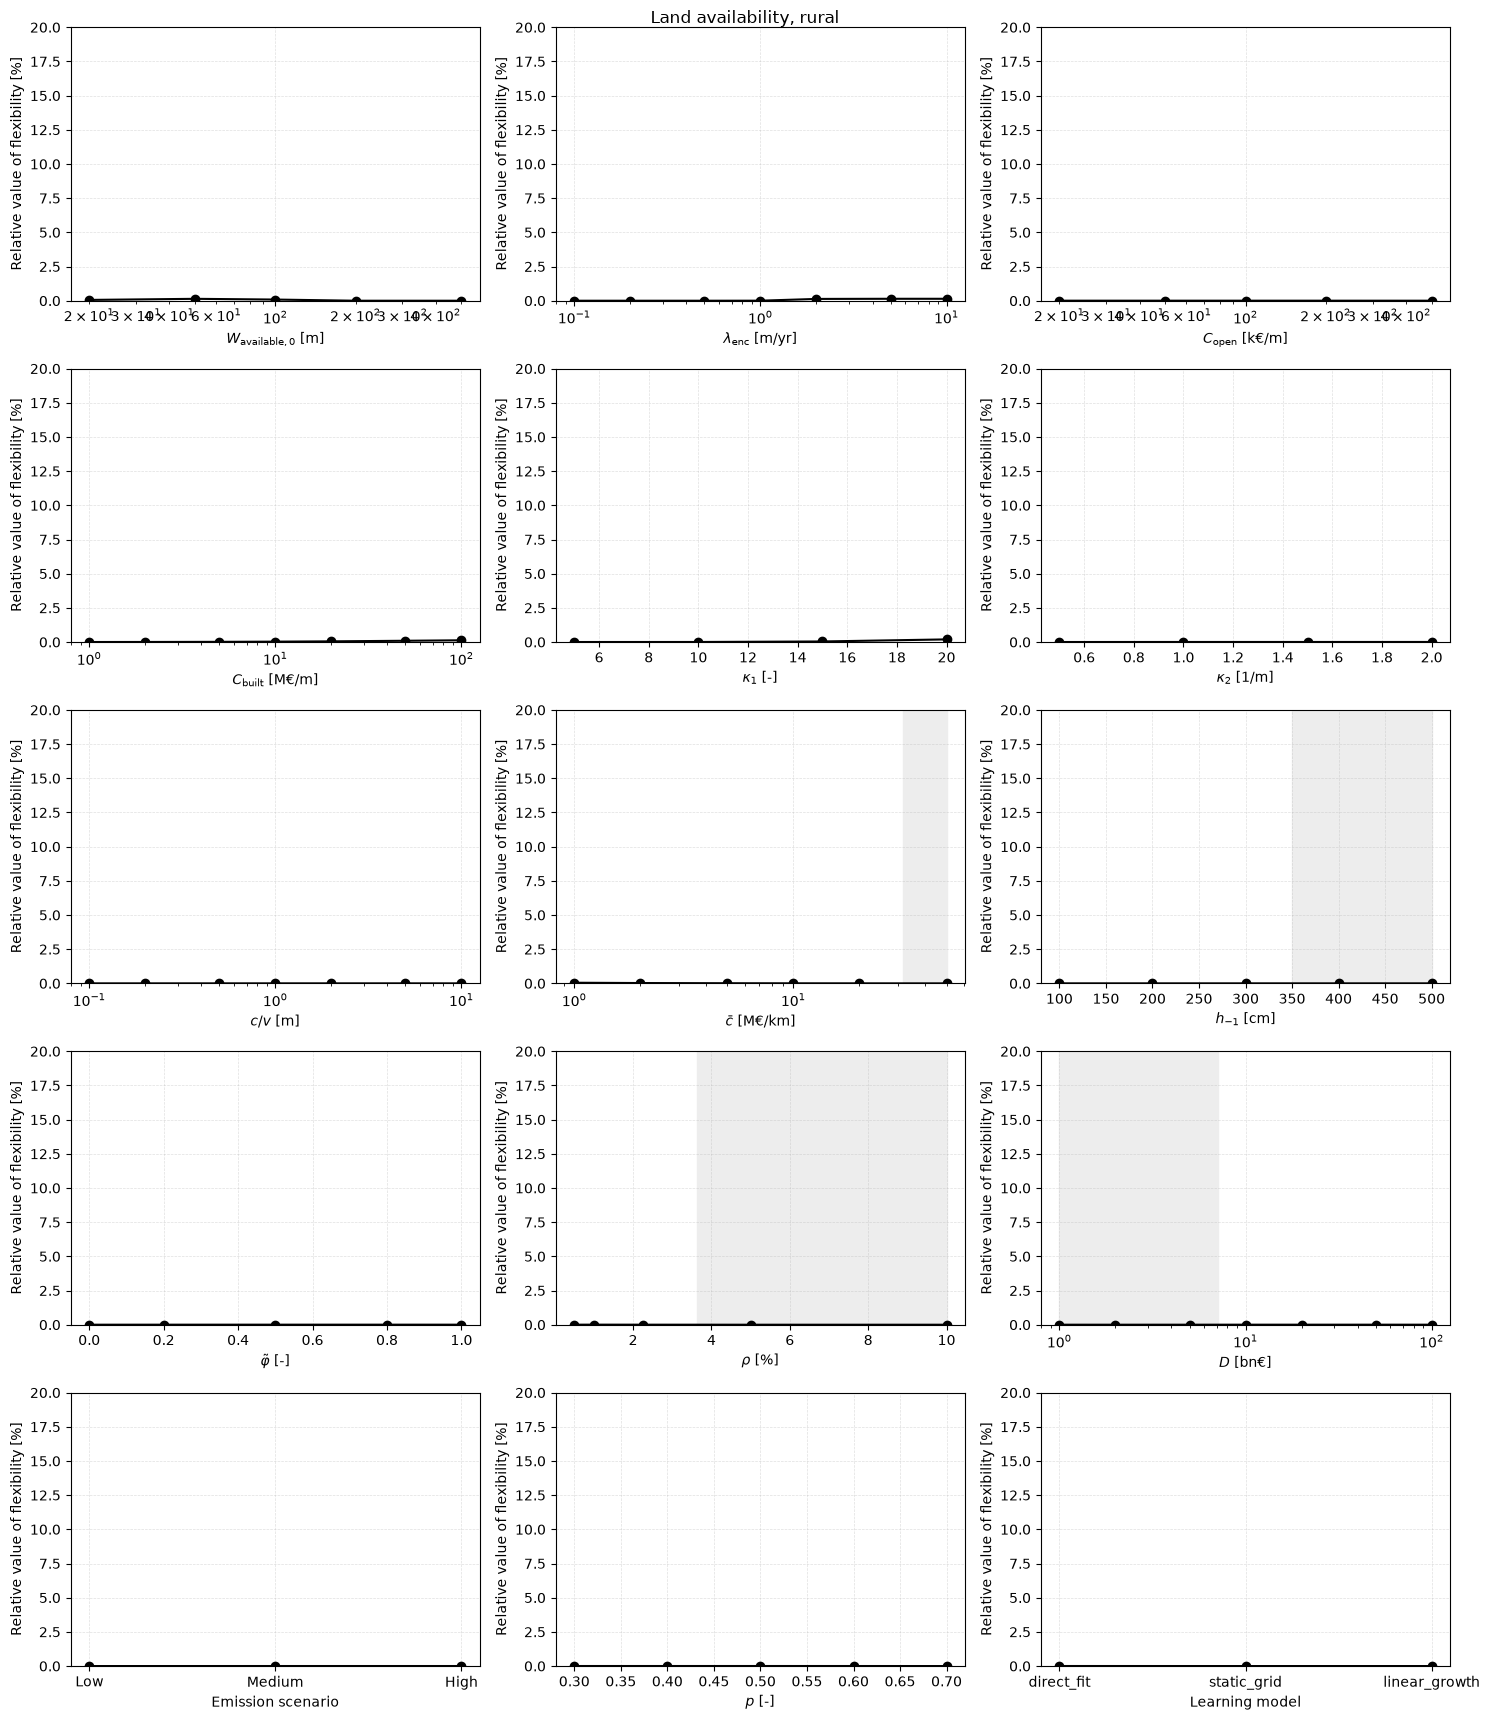

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
kappa_1         0.0        0.2        0.2
lambda_enc      0.0        0.1        0.1
W_available_0   0.0        0.1        0.1
C_built         0.0        0.1        0.1
c_bar           0.0        0.0        0.0
rho             0.0        0.0        0.0
kappa_2         0.0        0.0        0.0
p               0.0        0.0        0.0
learning_model  0.0        0.0        0.0
phi             0.0        0.0        0.0
c/v             0.0        0.0        0.0
D               0.0        0.0        0.0
w               0.0        0.0        0.0
C_open          0.0        0.0        0.0
h_minus_1       0.0        0.0        0.0


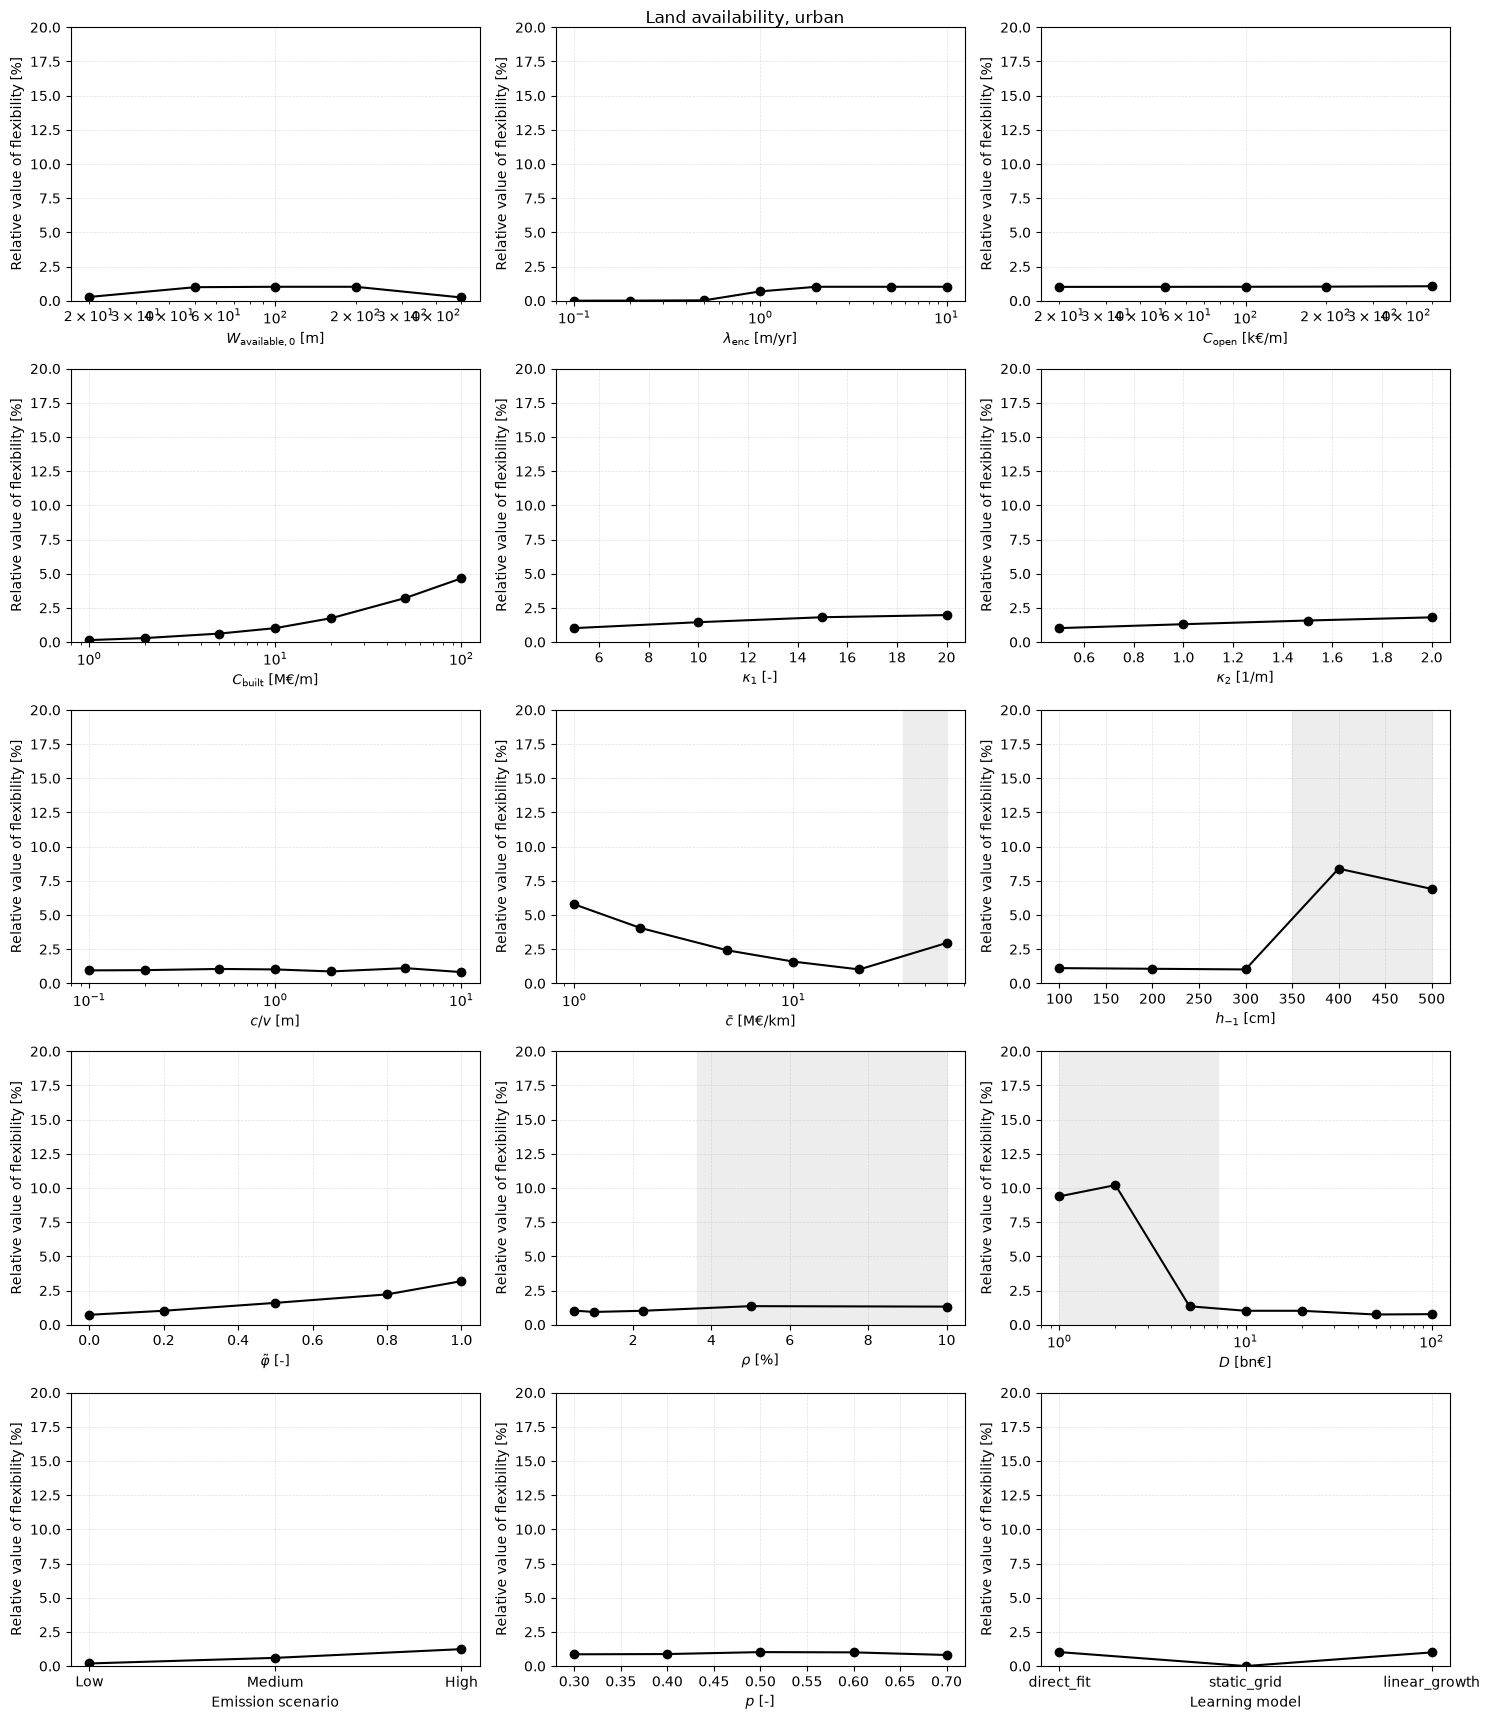

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
D               0.7        10.2       9.5
h_minus_1       1.0        8.4        7.4
c_bar           1.0        5.8        4.8
C_built         0.1        4.7        4.5
phi             0.7        3.2        2.5
w               0.2        1.2        1.0
learning_model  0.0        1.0        1.0
lambda_enc      0.0        1.0        1.0
kappa_1         1.0        2.0        1.0
kappa_2         1.0        1.8        0.8
W_available_0   0.2        1.0        0.8
rho             0.9        1.4        0.4
c/v             0.8        1.1        0.3
p               0.8        1.0        0.2
C_open          1.0        1.1        0.0


In [19]:
for name, cost_model in land_cost_models.items():
    plot_sweeps(land_sweeps[name], model_sweeps(cost_model), f"Land availability, {name}")

### Convergence

Numerical parameters. The end year sweep coarsens the height grid of the retention model for longer horizons.

In [20]:
%%cache sweeps_convergence
convergence_sweeps = {
    **{name: run_sweeps(numerical_sweeps(backward_kwargs, land=False), cost_model, backward_kwargs) for name, cost_model in retention_cost_models.items()},
    **{name: run_sweeps(numerical_sweeps(land_backward_kwargs, land=True), cost_model, land_backward_kwargs) for name, cost_model in land_cost_models.items()},
}

[cache hit: 'sweeps_convergence' (007ae3b369)]


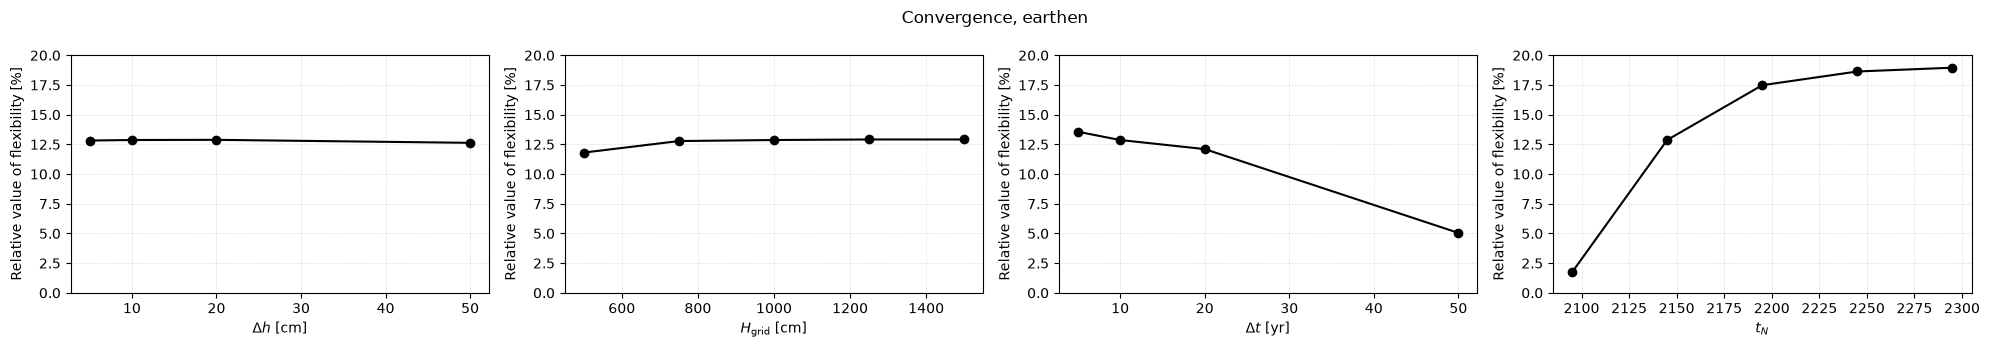

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
end_year        1.7        19.0       17.2
step            5.0        13.6       8.5
max_possible_h  11.8       12.9       1.1
h_step          12.6       12.9       0.3


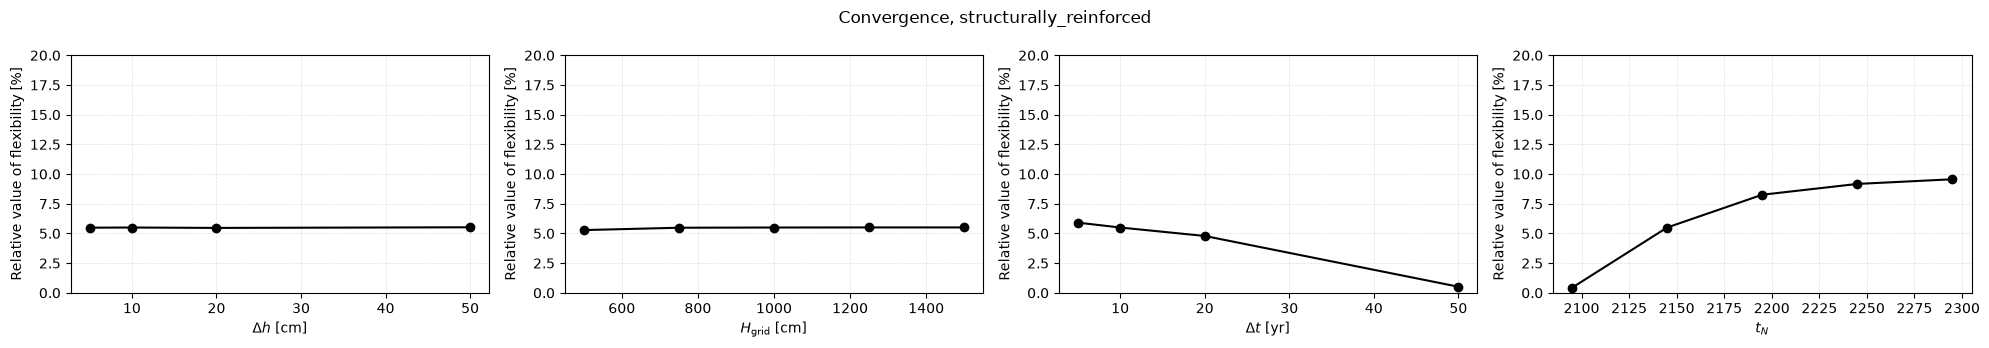

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
end_year        0.4        9.6        9.1
step            0.5        5.9        5.4
max_possible_h  5.3        5.5        0.2
h_step          5.5        5.5        0.1


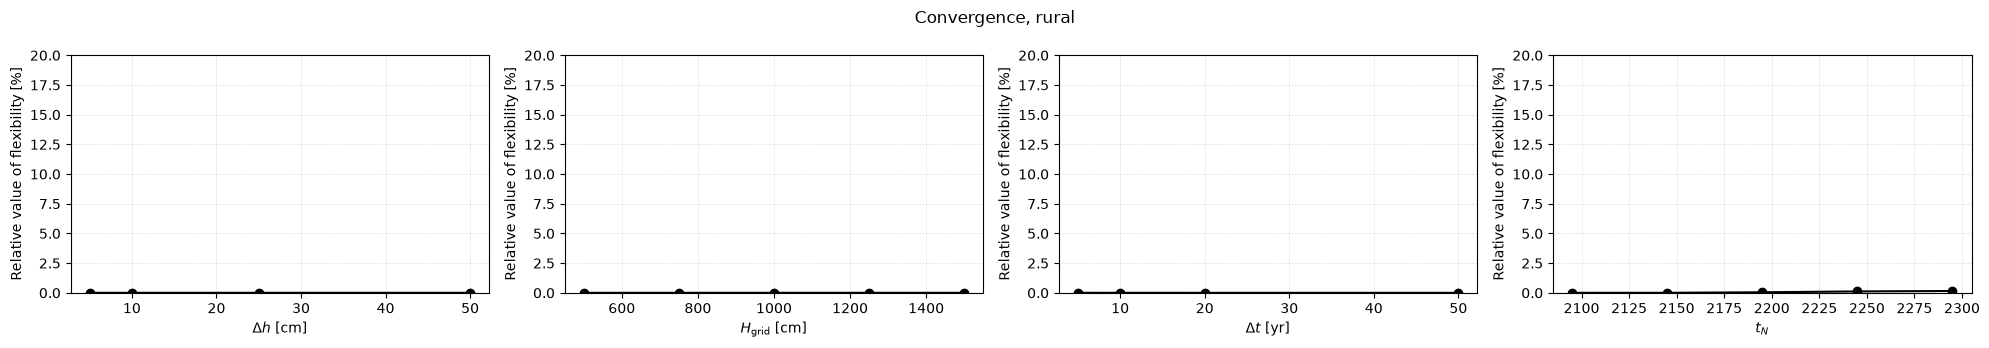

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
end_year        0.0        0.2        0.2
step            0.0        0.0        0.0
max_possible_h  0.0        0.0        0.0
h_step          0.0        0.0        0.0


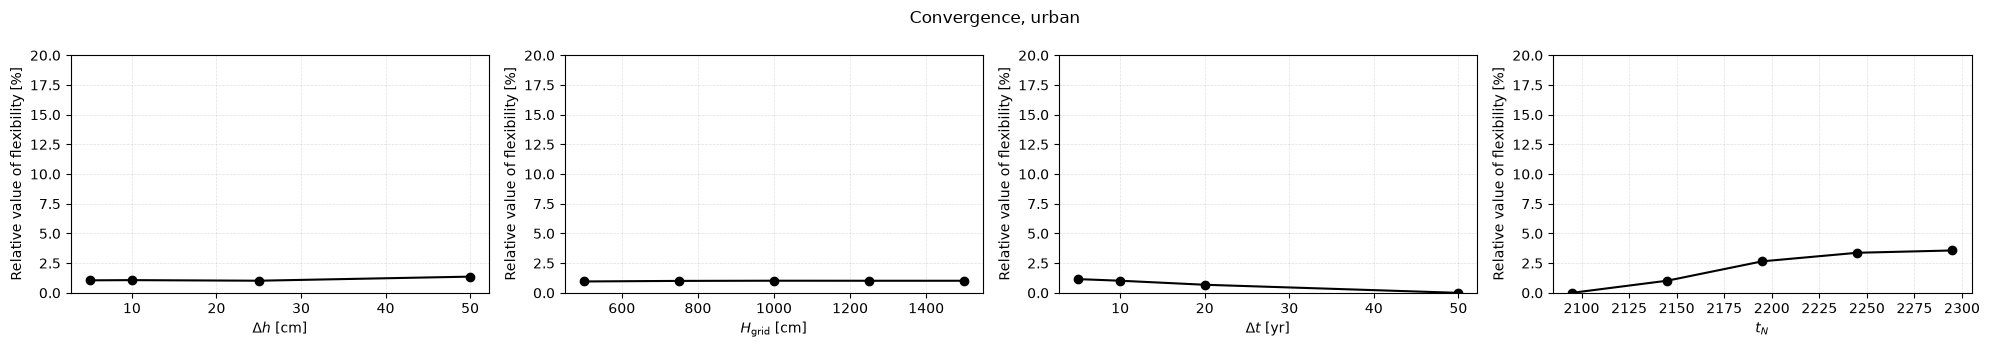

Sweep           Min [%]    Max [%]    Spread [p.p.]
--------------  ---------  ---------  ---------------
end_year        0.0        3.6        3.6
step            0.0        1.2        1.2
h_step          1.0        1.4        0.3
max_possible_h  1.0        1.0        0.1


In [21]:
for name, results in convergence_sweeps.items():
    land = name in land_cost_models
    sweeps = numerical_sweeps(land_backward_kwargs if land else backward_kwargs, land)
    plot_sweeps(results, sweeps, f"Convergence, {name}", ncols=4)

### Multiple Parameters

All of the four model parameters with the largest spread of the relative value of flexibility (see the tables above), and the end year, set together to their values with the largest relative value of flexibility one at a time (thesis Sections 7.1.5 and 7.2.5). The effects may be non-additive, so the result may not be the largest attainable value.

In [22]:
MULTI_FACTORS = {
    "earthen": {
        "weights": [0.0, 0.0, 1.0], "c": 70e6 / 11, "v": 700e6 / 11, "discount_rate": 0.01, "phi_minus_1": 1.0,
        "end_year": 2300, "h_step": 0.25, "max_possible_h": 25,
    },
    "structurally_reinforced": {
        "c": 200e6 / 11, "v": 2000e6 / 11, "weights": [0.0, 0.0, 1.0], "discount_rate": 0.01, "phi_minus_1": 1.0,
        "end_year": 2300, "h_step": 0.25, "max_possible_h": 25,
    },
    "rural": {
        "kappa_1": 20.0, "lambda_enc": 5.0, "W_available_0": 50.0, "C_built": 1e8,
        "end_year": 2300, "h_step": 0.25, "max_possible_h": 25,
    },
    "urban": {
        "D": 2e9, "h_minus_1": 4.0, "h_ref": 4.0, "c": 5e6, "v": 5e6, "C_built": 1e8,
        "end_year": 2300, "h_step": 0.25, "max_possible_h": 25,
    },
}  # c/v = 1/10 m at the baseline c + v * 1 m; urban: c_bar = 1 M€/km

In [23]:
%%cache multi_factor
multi_results = {}
for name, factors in MULTI_FACTORS.items():
    cost_model, kwargs = (land_cost_models[name], land_backward_kwargs) if name in land_cost_models else (retention_cost_models[name], backward_kwargs)
    multi_results[name] = sweep_designs(tuple(factors), [tuple(factors.values())], sea_level_rise_model, risk_model, cost_model, kwargs)

[cache hit: 'multi_factor' (25f679b8d5)]


In [24]:
baseline_rewards = retention_rewards | land_rewards
for name, swept in multi_results.items():
    baseline = design_summary({name: baseline_rewards[name]}, table=False)["Relative VoF [%]"].iloc[0]
    print(f"{name}: relative VoF {baseline:.1f} % (baseline) -> {sweep_results(swept)['relative_vof'][0] * 100:.1f} % (all together)")

earthen: relative VoF 12.9 % (baseline) -> 28.2 % (all together)
structurally_reinforced: relative VoF 5.5 % (baseline) -> 36.1 % (all together)
rural: relative VoF 0.0 % (baseline) -> 0.0 % (all together)
urban: relative VoF 1.0 % (baseline) -> 43.2 % (all together)
